# 08 · EDM preconditioning, consistency and few-step generation

Separate a better numerical sampler from a model trained to jump across a trajectory. Inspect boundary conditions and the real refinement failures.

**Prerequisites:** 01–05; denoising, ODE integration and detached training targets.

**By the end:** Explain EDM scales and its sigma clock; compare Karras grids with measured calls; check consistency boundaries; train a small consistency student and distinguish CT/CD/iCT/progressive distillation.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. EDM uses noise standard deviation as a coordinate

With $x=x_0+\sigma\epsilon$, EDM predicts a denoiser
$$D_\theta(x,\sigma)=c_{skip}x+c_{out}F_\theta(c_{in}x,c_{noise}),$$
$$c_{skip}=\frac{\sigma_d^2}{\sigma^2+\sigma_d^2},\quad
c_{out}=\frac{\sigma\sigma_d}{\sqrt{\sigma^2+\sigma_d^2}},\quad
c_{in}=\frac1{\sqrt{\sigma^2+\sigma_d^2}},\quad c_{noise}=\tfrac14\log\sigma.$$
Train with log-normal sigma and weight $\lambda(\sigma)=\sigma^{-2}+\sigma_d^{-2}$.
$\sigma_d$ is a data-scale design choice, not the noisy variance at every sigma.
**Code:** `EDMPreconditioner`, `edm_loss` in [edm.py](../diffusion_lab/edm.py).

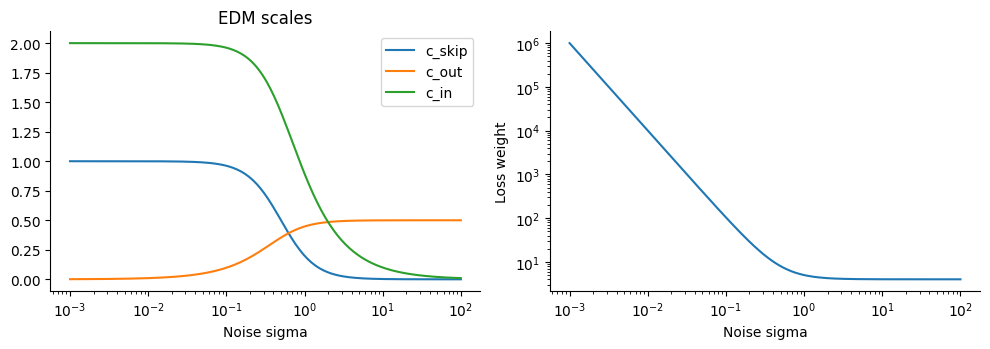

In [2]:
from diffusion_lab.edm import EDMPreconditioner, edm_sample, karras_sigmas
from diffusion_lab.models import Conditioning, TimeMLP

sigma = torch.logspace(-3, 2, 200)
sd = 0.5
fig, axes = plt.subplots(1, 2)
axes[0].semilogx(sigma, sd**2 / (sigma**2 + sd**2), label="c_skip")
axes[0].semilogx(sigma, sigma * sd / (sigma**2 + sd**2).sqrt(), label="c_out")
axes[0].semilogx(sigma, (sigma**2 + sd**2).rsqrt(), label="c_in")
axes[0].set(xlabel="Noise sigma", title="EDM scales")
axes[0].legend()
axes[1].loglog(sigma, sigma.reciprocal().square() + sd**-2)
axes[1].set(xlabel="Noise sigma", ylabel="Loss weight")
plt.tight_layout()
plt.show()
wrapper = EDMPreconditioner(TimeMLP(width=32, depth=1), sigma_data=sd)
assert wrapper(torch.randn(8, 2), torch.ones(8)).shape == (8, 2)

## 2. Karras grid and probability-flow integration

For additive Gaussian corruption with sigma as clock,
$$dx/d\sigma=(x-D(x,\sigma))/\sigma.$$
The descending Karras grid interpolates $\sigma^{1/\rho}$ linearly and appends zero.
Heun uses two denoiser calls except the final Euler step to zero (no division by zero),
so $N$ steps cost $2N-1$ branch calls at CFG 1. Stochastic churn is optional and is off below.
We use an analytic denoiser to isolate discretization from training.

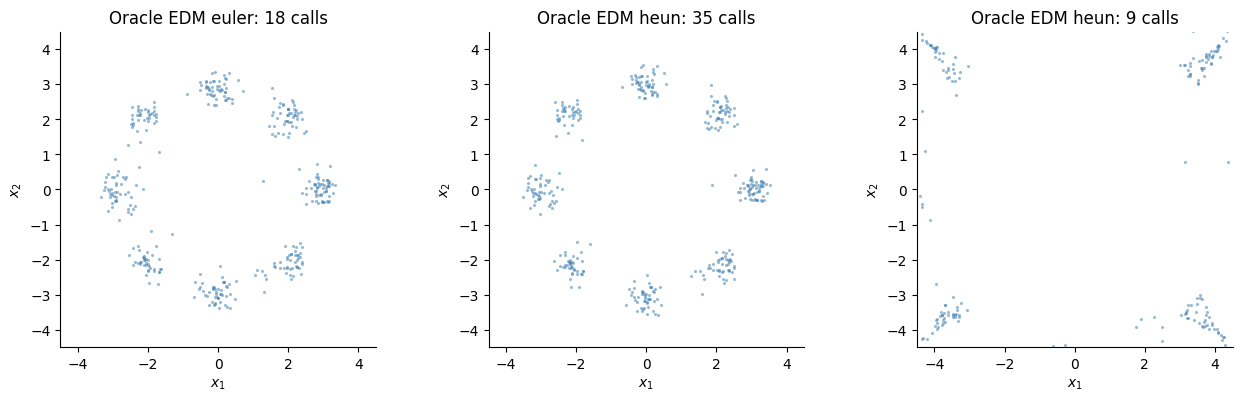

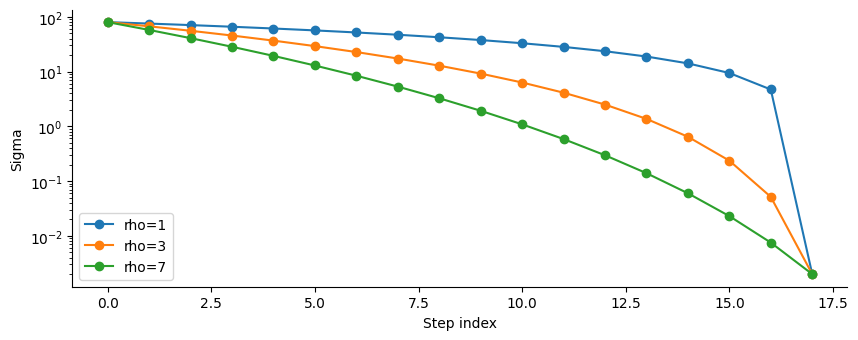

Initial sigma=80 Gaussian prior is approximate for this finite-time GMM.


In [3]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.paths import expand

mixture = GaussianMixture()


class OracleDenoiser(torch.nn.Module):
    def forward(self, x, sigma, labels=None):
        score = mixture.score(x, torch.ones_like(sigma), sigma, labels)
        return x + expand(sigma.square(), x) * score


oracle = OracleDenoiser()
initial = torch.randn(384, 2, generator=torch.Generator().manual_seed(111))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (method, steps) in zip(axes, [("euler", 18), ("heun", 18), ("heun", 5)], strict=True):
    samples, history, calls = edm_sample(oracle, initial, steps=steps, solver=method)
    assert calls == steps if method == "euler" else calls == 2 * steps - 1
    scatter(ax, samples, f"Oracle EDM {method}: {calls} calls")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots()
for rho in [1.0, 3.0, 7.0]:
    grid = karras_sigmas(18, rho=rho)
    ax.semilogy(range(18), grid[:-1], "o-", label=f"rho={rho:g}")
ax.set(xlabel="Step index", ylabel="Sigma")
ax.legend()
plt.show()
print("Initial sigma=80 Gaussian prior is approximate for this finite-time GMM.")

## 3. A consistency map has a boundary condition

A consistency function maps points on one PF-ODE trajectory to its low-noise endpoint:
$F(x_\sigma,\sigma)=F(x_{\sigma'},\sigma')$.
At $\sigma_{min}$ require identity. The repository uses
$$c_{skip}=\frac{\sigma_d^2}{(\sigma-\sigma_{min})^2+\sigma_d^2},\quad
c_{out}=\frac{\sigma_d(\sigma-\sigma_{min})}{\sqrt{\sigma^2+\sigma_d^2}}.$$
This differs from ordinary EDM preconditioning: it makes the boundary exact.

| Method | Neighbor target |
|---|---|
| CT | Shared-noise adjacent states, detached EMA target |
| CD | Teacher PF-ODE step, detached target student |
| iCT | Detached **online** student, lognormal interval sampling, Pseudo-Huber and scale schedule |
| Progressive DDIM distillation | Two deterministic teacher steps matched by one student step |

Inference EMA and a training target EMA have different roles.
**Code:** [consistency.py](../diffusion_lab/consistency.py), [progressive.py](../diffusion_lab/progressive.py).

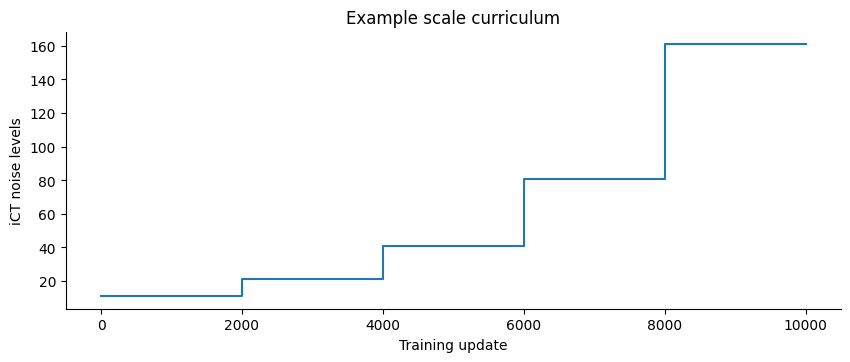

In [4]:
from diffusion_lab.consistency import (
    ConsistencyModel,
    consistency_loss,
    consistency_sample,
    improved_scales,
)

torch.manual_seed(112)
backbone = TimeMLP(width=64, depth=2)
backbone.condition = Conditioning(64, 0, time_embedding="positional")
student = ConsistencyModel(backbone, sigma_min=0.002, sigma_data=0.5)
x = torch.randn(32, 2)
torch.testing.assert_close(student(x, torch.full((32,), student.sigma_min)), x, atol=0, rtol=0)
plt.step(
    range(0, 10001, 250),
    [improved_scales(s, 10000, 10, 160) for s in range(0, 10001, 250)],
    where="post",
)
plt.xlabel("Training update")
plt.ylabel("iCT noise levels")
plt.title("Example scale curriculum")
plt.show()

## 4. Short CPU consistency distillation

Use the exact GMM denoiser as a teacher and a separate EMA target student.
This is a small CD demonstration, not the published training budget/architecture.
The oracle teacher guides neighboring states; the student still must learn the
trajectory endpoint map. A lower neighbor loss alone does not prove good one-step samples.

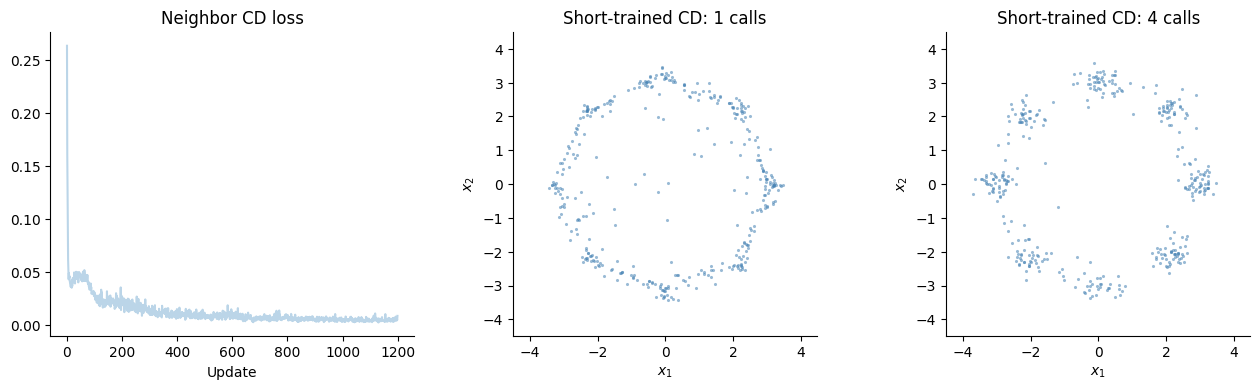

In [5]:
import copy

target = copy.deepcopy(student).eval().requires_grad_(False)
optimizer = torch.optim.Adam(student.parameters(), lr=0.001)
g = torch.Generator().manual_seed(113)
losses = []
for _step in range(1200):
    clean, _ = mixture.sample(256, g)
    loss = consistency_loss(
        student,
        target,
        clean,
        None,
        intervals=20,
        sigma_max=10,
        teacher=oracle,
        generator=g,
        weighting="inverse_gap",
    ).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        for destination, source in zip(target.parameters(), student.parameters(), strict=True):
            destination.lerp_(source, 0.05)
    losses.append(loss.item())
student.eval()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].plot(losses, alpha=0.3)
axes[0].set(title="Neighbor CD loss", xlabel="Update")
for ax, steps in zip(axes[1:], [1, 4], strict=True):
    generated, _, calls = consistency_sample(
        target, initial, steps=steps, sigma_max=10, generator=torch.Generator().manual_seed(114)
    )
    scatter(ax, generated, f"Short-trained CD: {calls} calls")
plt.tight_layout()
plt.show()

## 5. Refinement is a measured hypothesis, not a guarantee

Consistency sampling re-noises a denoised estimate to each requested noise
level and applies the map again. Model error, chosen levels, clipping and
training target affect whether extra calls improve samples.
The actual revised CIFAR CD model achieved one-call FID 24.27 versus old 27.66,
but two-call FID worsened to 42.58 and four-call remained 100.57 (5k/5k).
Four-call iCT reached 43.10, improving its own one-call result but trailing one-call CD.
These results have one training seed; different recipes/budgets are not a causal ablation of one change.

Actual 40k CIFAR CD, one call; rows are requested classes


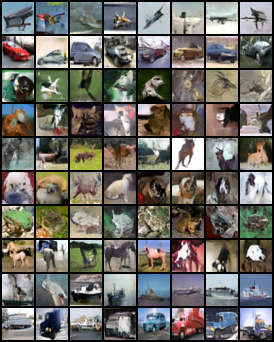

{'nfe_per_image': 1, 'fid_2048': 24.271270751953125, 'inception_score_mean': 7.6673760414123535, 'real_count': 5000, 'generated_count': 5000}
{'nfe_per_image': 2, 'fid_2048': 42.58097457885742, 'inception_score_mean': 7.8255615234375, 'real_count': 5000, 'generated_count': 5000}
{'nfe_per_image': 4, 'fid_2048': 100.57136535644531, 'inception_score_mean': 5.888680934906006, 'real_count': 5000, 'generated_count': 5000}


In [6]:
saved_gallery(
    "assets/studies/scratch_refinement/cd_vs_old/candidate_final_1/classes.png",
    "Actual 40k CIFAR CD, one call; rows are requested classes",
)
for calls in [1, 2, 4]:
    report = json.loads(
        (
            project
            / f"assets/studies/scratch_refinement/cd_vs_old/candidate_final_{calls}/metrics.json"
        ).read_text()
    )
    print(
        {
            k: report[k]
            for k in [
                "nfe_per_image",
                "fid_2048",
                "inception_score_mean",
                "real_count",
                "generated_count",
            ]
        }
    )

## Exercises and worked answers

1. Why append zero to the EDM grid but avoid evaluating the denoiser at zero?
2. Why is a detached online iCT target different from an EMA target?
3. Design a fair comparison of one/four calls: fix weights, guidance, counts and evaluation seed; select levels on separate examples.

<details><summary>Worked answers</summary>

1. The final endpoint should be denoised, but log sigma and drift divisions are singular. Final Euler returns the current denoiser estimate without a zero-sigma network call.
2. Stop-gradient changes differentiation, not the target weights. Online target uses current weights; EMA averages previous updates and defines a different objective.
3. Report actual branch calls, timing and uncertainty; compare shared datasets/protocols. Do not select settings on the final evaluation results.

</details>

**Full recipes:** [Consistency chapter](../docs/10_consistency_models.md), [few-step chapter](../docs/18_stronger_few_step_generation.md), [final refinement](../docs/28_scratch_and_refinement.md).
**Continue:** [Latent diffusion and DiT](09_latent_diffusion_and_dit.ipynb).
**Sources:** [EDM](https://arxiv.org/abs/2206.00364), [consistency](https://arxiv.org/abs/2303.01469), [iCT](https://arxiv.org/abs/2310.14189).